# 03 · `gmsEDA` vs NeuroKit2 vs sparsEDA decompositions (no per-subject normalisation)

Notebook 02 showed that `gmsEDA` features (20 chops, overlap 0.9, λ-scale 1) raise LOSO accuracy from 0.840
to 0.866 without per-subject normalisation. **Do standard decompositions do the same?** Two families are compared:
NeuroKit2's filter-based methods and **sparsEDA** (Hernando-Gallego et al., 2018), which, like `gmsEDA`, models
the EDA as a smooth tonic level plus a *sparse* SCR driver convolved with a response kernel.

NeuroKit2 decompositions compared (all on the same 1-min windows, in µS):

| name | NeuroKit2 call | what it does |
|---|---|---|
| `nk_highpass` | `nk.eda_phasic(w, 4, method="highpass")` (**NeuroKit2's default**) | tonic = 2nd-order Butterworth low-pass at 0.05 Hz, phasic = high-pass at 0.05 Hz (zero-phase `sosfiltfilt`) |
| `nk_median` | `nk.eda_phasic(w, 4, method="smoothmedian")` | tonic = 4-s running median (`scipy.signal.medfilt`), phasic = signal − tonic |
| `nk_cvxeda` | `nk.eda_phasic(w, 4, method="cvxeda")` | only if `cvxopt` is installed (see the last section) |
| `sparsEDA` | `nk.eda_phasic(w, 4, method="sparsEDA")` | resample to 8 Hz, non-negative LARS fit of a linear tonic basis + sparse bi-exponential SCR driver |

**Every decomposition is applied to each 1-min window on its own**, exactly like `gmsEDA` in notebook 02. sparsEDA
was designed for longer signals (≥ 80 s); it pads the window internally (20 s before, 60 s after) as in NeuroKit2.

**Implementation note.** The NeuroKit2 methods are run with the real `neurokit2` (version printed below; the
results here used your installed NeuroKit2 0.2.13). `eda_utils` also contains line-for-line copies
(`nk_eda_phasic`, `sparsEDA`) used only as a fallback when `neurokit2` is not installed. The first code cell
checks that the copies give identical output to `nk.eda_phasic`.

**sparsEDA and its driver.** NeuroKit2's `_eda_phasic_sparsEDA` computes the sparse SCR driver but only returns
tonic and phasic. It also **crashes (`IndexError`) on 1-min windows in which no positive driver is found**, in its
driver post-processing step, which runs after tonic and phasic are already computed. sparsEDA is therefore run
with `eda_utils.sparsEDA`, a copy of the NeuroKit2 code that (a) also returns the driver (moved from 8 Hz to the
4 Hz grid by summing impulses) and (b) returns an all-zero driver instead of crashing. Its tonic and phasic are
identical to `nk.eda_phasic(method="sparsEDA")` wherever NeuroKit2 runs (checked in the first cell).

**Features.** Each decomposition goes through the *same* feature function as `gmsEDA` (`gms_signed_features`):
tonic (5), phasic (8) and scale-free ratios. NeuroKit2's filter methods have no sparse driver, so for them the 9
driver features are dropped. `gmsEDA` and `sparsEDA` are shown both **with and without** their driver features.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings, time
warnings.filterwarnings("ignore")
from eda_utils import *
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

WINDOWING = "reshape"   # "reshape" (default: eda_proj.features.reshape_function) or "block"; see notebook 01
LABELS = (1, 2)         # WESAD conditions in the task: 1 baseline, 2 stress, 3 amusement, 4 meditation
MERGE = {}              # optional label merging, e.g. {3: 1} = amusement counted with baseline (stress vs non-stress)
STRIDE = 10
# per-window caches (decompositions, features) live in cache/<WINDOWING>/label<k>/ and are combined for LABELS;
# results that depend on the task (screening, nested selection) live in RES:
RES = results_dir(WINDOWING, LABELS, MERGE)
W, meta = load_windows(WINDOWING, LABELS, STRIDE)
y, groups = task_labels(meta, MERGE), meta.subject.values

try:
    import neurokit2 as nk
    HAVE_NK = True
    print("neurokit2", nk.__version__, "found")
    chk = range(0, len(W), 25)
    for m in ["highpass", "smoothmedian"]:
        d = max(np.abs(nk.eda_phasic(W[i], sampling_rate=FS, method=m).values - np.c_[nk_eda_phasic(W[i], method=m)]).max() for i in chk)
        print(f"  {m}: max |copy - nk| over {len(chk)} windows = {d:.2e}")
    d, crash = 0.0, 0
    for i in chk:
        try:
            ref = nk.eda_phasic(W[i], sampling_rate=FS, method="sparsEDA")
            d = max(d, np.abs(ref.values - np.c_[sparsEDA(W[i])[:2]]).max())
        except IndexError:
            crash += 1
    print(f"  sparsEDA: max |copy - nk| = {d:.2e}; nk.eda_phasic crashed on {crash} of {len(chk)} windows (no positive driver)")
except ImportError:
    HAVE_NK = False
    print("neurokit2 not installed -> using the copies in eda_utils (nk_eda_phasic, sparsEDA)")

def decompose(w, method):
    if HAVE_NK:
        d = nk.eda_phasic(w, sampling_rate=FS, method=method)
        return d.EDA_Tonic.values, d.EDA_Phasic.values
    return nk_eda_phasic(w, method=method)

neurokit2 0.2.13 found
  highpass: max |copy - nk| over 103 windows = 0.00e+00
  smoothmedian: max |copy - nk| over 103 windows = 0.00e+00
  sparsEDA: max |copy - nk| = 0.00e+00; nk.eda_phasic crashed on 16 of 103 windows (no positive driver)


## 1. NeuroKit2 features for every window

In [2]:
t0 = time.time()
NK = {"nk_highpass": own_features(WINDOWING, LABELS, "nk_highpass"),     # cached per label: decompfeat_<method>.csv
      "nk_median": own_features(WINDOWING, LABELS, "nk_median")}
print(f"{time.time() - t0:.0f}s", {k: v.shape for k, v in NK.items()})

0s {'nk_highpass': (2575, 17), 'nk_median': (2575, 17)}


## 1b. sparsEDA features (each 1-min window)

In [3]:
t0 = time.time()
SP = {"sparsEDA": own_features(WINDOWING, LABELS, "sparsEDA")}            # cached per label
SP_T, SP_P, SP_D = sparsEDA_windows(W)          # the decomposition itself, for the statistics and the figure below
print(f"{time.time() - t0:.0f}s")
print("driver non-zeros per window: %.2f; windows without any driver event: %d of %d"
      % ((SP_D > 0).sum(1).mean(), int(((SP_D > 0).sum(1) == 0).sum()), len(W)))

28s
driver non-zeros per window: 2.38; windows without any driver event: 415 of 2575


### What the decompositions look like (same windows as in notebook 02)
Black = EDA, orange = tonic, green = phasic (right axis), red = sparse driver (right axis).

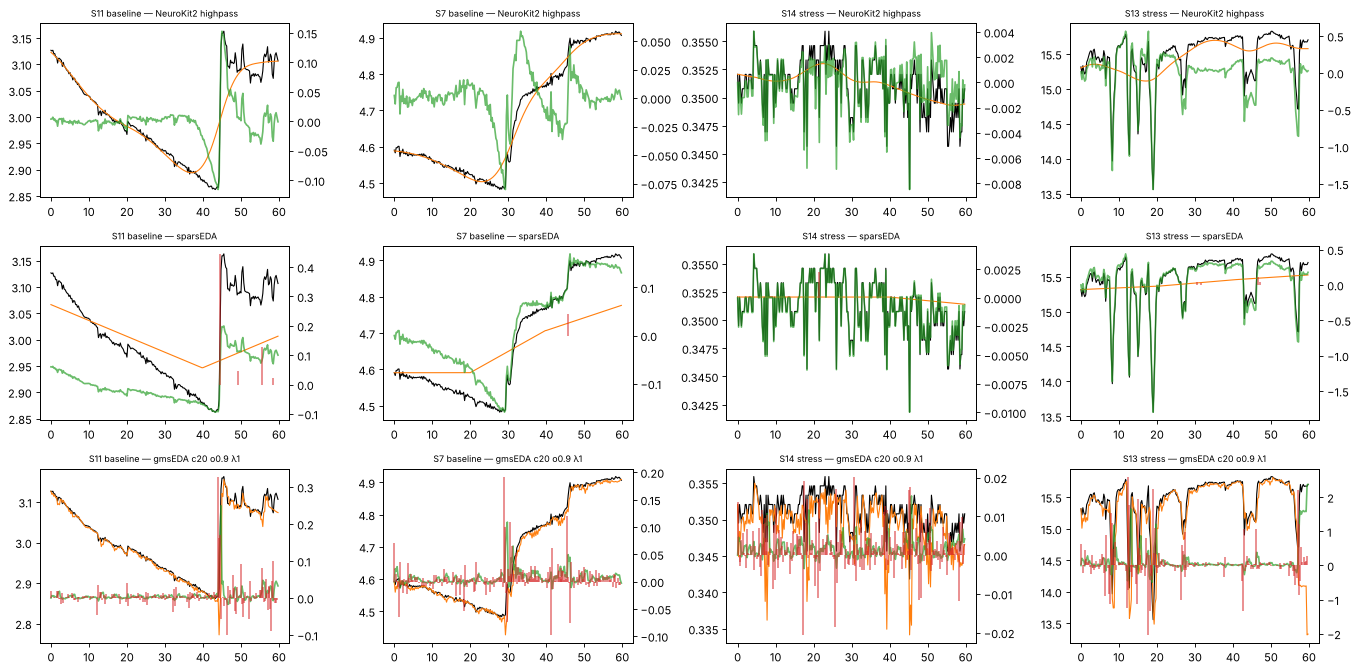

In [4]:
rng = np.random.default_rng(3)
idx = list(rng.choice(np.flatnonzero(y == 1), 2, replace=False)) + list(rng.choice(np.flatnonzero(y == 2), 2, replace=False))
t = np.arange(WIN) / FS
fig, axes = plt.subplots(3, 4, figsize=(17, 8.5))
for col, i in enumerate(idx):
    s = meta.subject[i]
    g = gmsEDA_window(W[i], 20, 0.9, 1, 0)
    comps = [("NeuroKit2 highpass", decompose(W[i], "highpass"), None),
             ("sparsEDA", (SP_T[i], SP_P[i]), SP_D[i]),
             ("gmsEDA c20 o0.9 λ1", (g[1], g[2]), g[0])]
    for row, (title, (ton, ph), drv) in enumerate(comps):
        ax = axes[row, col]
        ax.plot(t, W[i], "k", lw=1); ax.plot(t, ton, color="tab:orange", lw=1)
        ax2 = ax.twinx(); ax2.plot(t, ph, color="tab:green", alpha=.7)
        if drv is not None:
            ax2.vlines(t, 0, drv, color="tab:red", alpha=.6)
        ax.set_title(f"{s} {'stress' if y[i] == 2 else 'baseline'} — {title}", fontsize=8)
plt.tight_layout(); plt.show()

## 2. LOSO comparison (4 classifiers)

In [5]:
R = own_features(WINDOWING, LABELS, "raw")
RAW = R[[c for c in R if not c.startswith("rel_")]]
BEST = "c20_o0.9_l1_nn0"
GMS = own_features(WINDOWING, LABELS, BEST)
GMS_NODRV = GMS[[c for c in GMS if "drv" not in c]]
print("feature counts:", {"raw": RAW.shape[1], "gms": GMS.shape[1], "gms w/o driver": GMS_NODRV.shape[1],
                          **{k: v.shape[1] for k, v in NK.items()}, **{k: v.shape[1] for k, v in SP.items()}})

SETS = {"raw": RAW}
for k, v in NK.items():
    SETS[f"raw + {k}"] = pd.concat([RAW, v], axis=1)
for k, v in SP.items():
    SETS[f"raw + {k} (tonic/phasic only)"] = pd.concat([RAW, v[[c for c in v if "drv" not in c]]], axis=1)
    SETS[f"raw + {k} (full)"] = pd.concat([RAW, v], axis=1)
SETS["raw + gmsEDA (tonic/phasic only)"] = pd.concat([RAW, GMS_NODRV], axis=1)
SETS["raw + gmsEDA (full)"] = pd.concat([RAW, GMS], axis=1)
for k, v in NK.items():
    SETS[f"{k} alone"] = v
for k, v in SP.items():
    SETS[f"{k} (full) alone"] = v
SETS["gmsEDA (full) alone"] = GMS

t0 = time.time()
res, ptab = compare_feature_sets(SETS, y, groups)
print(f"{time.time() - t0:.0f}s")
acc = res.pivot(index="features", columns="model", values="acc").loc[list(SETS)]
acc["mean"] = acc.mean(axis=1)
acc.round(3)

feature counts: {'raw': 33, 'gms': 28, 'gms w/o driver': 17, 'nk_highpass': 17, 'nk_median': 17, 'sparsEDA': 28}
247s


model,HistGB,LogReg,RandomForest,SVM-RBF,mean
features,,,,,
raw,0.843,0.833,0.829,0.855,0.840
raw + nk_highpass,0.855,0.831,0.842,0.857,0.846
raw + nk_median,0.849,0.831,0.847,0.867,0.849
raw + sparsEDA (tonic/phasic only),0.842,0.830,0.839,0.856,0.842
raw + sparsEDA (full),0.838,0.829,0.843,0.851,0.840
raw + gmsEDA (tonic/phasic only),0.846,0.842,0.833,0.875,0.849
raw + gmsEDA (full),0.859,0.866,0.855,0.882,0.866
nk_highpass alone,0.810,0.792,0.845,0.833,0.820
nk_median alone,0.817,0.774,0.837,0.839,0.817


In [6]:
f1 = res.pivot(index="features", columns="model", values="f1").loc[list(SETS)]
f1["mean"] = f1.mean(axis=1)
f1.round(3)

model,HistGB,LogReg,RandomForest,SVM-RBF,mean
features,,,,,
raw,0.825,0.808,0.809,0.833,0.819
raw + nk_highpass,0.837,0.805,0.824,0.836,0.826
raw + nk_median,0.832,0.804,0.831,0.848,0.829
raw + sparsEDA (tonic/phasic only),0.823,0.804,0.821,0.836,0.821
raw + sparsEDA (full),0.819,0.803,0.826,0.830,0.819
raw + gmsEDA (tonic/phasic only),0.828,0.819,0.816,0.857,0.830
raw + gmsEDA (full),0.844,0.848,0.839,0.866,0.849
nk_highpass alone,0.791,0.756,0.827,0.808,0.796
nk_median alone,0.797,0.730,0.821,0.815,0.791


### Paired per-subject test against `raw`
Each cell gives Δ mean subject accuracy (subjects improved / worse, Wilcoxon p).

In [7]:
ptab.assign(cell=lambda d: d.apply(lambda r: f"{r.delta:+.3f} ({r.wins}/{r.losses}, p={r.p:.3f})", axis=1)) \
    .pivot(index="features", columns="model", values="cell").loc[list(SETS)[1:]]

model,HistGB,LogReg,RandomForest,SVM-RBF
features,,,,
raw + nk_highpass,"+0.012 (10/4, p=0.096)","-0.002 (6/7, p=0.701)","+0.014 (9/5, p=0.397)","+0.002 (5/6, p=0.533)"
raw + nk_median,"+0.006 (9/4, p=0.221)","-0.002 (7/6, p=0.972)","+0.019 (10/2, p=0.071)","+0.012 (10/2, p=0.028)"
raw + sparsEDA (tonic/phasic only),"-0.002 (4/4, p=0.674)","-0.003 (7/7, p=0.925)","+0.010 (9/4, p=0.507)","+0.001 (6/8, p=0.975)"
raw + sparsEDA (full),"-0.005 (6/7, p=0.382)","-0.004 (7/6, p=0.972)","+0.014 (9/4, p=0.279)","-0.004 (5/9, p=0.433)"
raw + gmsEDA (tonic/phasic only),"+0.003 (10/4, p=0.103)","+0.010 (8/6, p=0.433)","+0.005 (8/4, p=0.367)","+0.020 (11/3, p=0.016)"
raw + gmsEDA (full),"+0.017 (11/3, p=0.198)","+0.033 (11/2, p=0.055)","+0.027 (11/3, p=0.056)","+0.027 (11/3, p=0.006)"
nk_highpass alone,"-0.033 (5/7, p=0.182)","-0.041 (5/10, p=0.015)","+0.016 (8/6, p=0.551)","-0.022 (4/11, p=0.105)"
nk_median alone,"-0.026 (5/9, p=0.140)","-0.059 (4/11, p=0.018)","+0.008 (7/6, p=0.780)","-0.016 (4/11, p=0.268)"
sparsEDA (full) alone,"-0.036 (2/11, p=0.033)","-0.039 (5/10, p=0.083)","+0.016 (8/6, p=0.272)","-0.030 (4/11, p=0.140)"


### Head-to-head: `raw + gmsEDA` vs `raw + NeuroKit2 highpass`

In [8]:
_, h2h = compare_feature_sets({"raw + nk_highpass": SETS["raw + nk_highpass"],
                               "raw + gmsEDA (full)": SETS["raw + gmsEDA (full)"],
                               "raw + gmsEDA (tonic/phasic only)": SETS["raw + gmsEDA (tonic/phasic only)"]},
                              y, groups, baseline="raw + nk_highpass")
h2h.round(3)

,features,model,delta,wins,losses,p
0,raw + gmsEDA (full),LogReg,0.035,12,2,0.030
1,raw + gmsEDA (full),SVM-RBF,0.025,12,1,0.003
2,raw + gmsEDA (full),RandomForest,0.014,9,3,0.158
3,raw + gmsEDA (full),HistGB,0.005,10,3,0.345
4,raw + gmsEDA (tonic/phasic only),LogReg,0.011,11,3,0.124
5,raw + gmsEDA (tonic/phasic only),SVM-RBF,0.018,10,4,0.016
6,raw + gmsEDA (tonic/phasic only),RandomForest,-0.009,5,8,0.807
7,raw + gmsEDA (tonic/phasic only),HistGB,-0.008,6,8,0.778


### Head-to-head: `raw + gmsEDA` vs the best sparsEDA variant

In [9]:
sp_best = max([k for k in SETS if k.startswith("raw + sparsEDA")], key=lambda k: acc.loc[k, "mean"])
print("best sparsEDA variant:", sp_best)
_, h2h_sp = compare_feature_sets({sp_best: SETS[sp_best], "raw + gmsEDA (full)": SETS["raw + gmsEDA (full)"]},
                                 y, groups, baseline=sp_best)
h2h_sp.round(3)

best sparsEDA variant: raw + sparsEDA (tonic/phasic only)


,features,model,delta,wins,losses,p
0,raw + gmsEDA (full),LogReg,0.036,11,3,0.055
1,raw + gmsEDA (full),SVM-RBF,0.026,12,3,0.007
2,raw + gmsEDA (full),RandomForest,0.017,10,3,0.087
3,raw + gmsEDA (full),HistGB,0.019,11,3,0.158


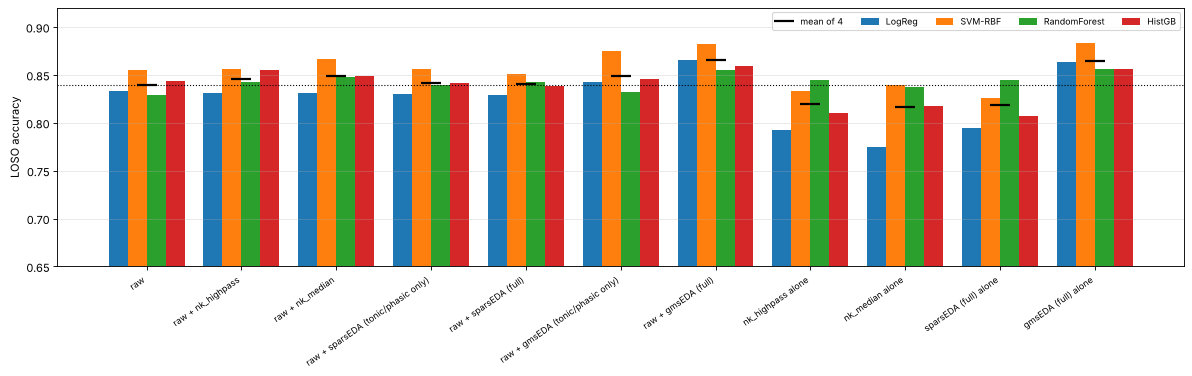

In [10]:
fig, ax = plt.subplots(figsize=(15, 4.8))
order = list(SETS)
xs = np.arange(len(order))
for j, m in enumerate(["LogReg", "SVM-RBF", "RandomForest", "HistGB"]):
    ax.bar(xs + (j - 1.5) * 0.2, acc.loc[order, m].values, width=0.2, label=m)
ax.plot(xs, acc.loc[order, "mean"].values, "k_", ms=18, mew=2, label="mean of 4")
ax.axhline(acc.loc["raw", "mean"], color="k", ls=":", lw=1)
ax.set_xticks(xs); ax.set_xticklabels(order, rotation=35, ha="right", fontsize=8)
ax.set_ylim(0.65, 0.92); ax.set_ylabel("LOSO accuracy"); ax.legend(fontsize=8, ncol=5); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

## 2b. No feature extraction: the 240 raw samples as input
The same four classifiers get the 1-min window itself (240 samples, µS) instead of features:
* `samples (240)`: the window as it is, so the absolute conductance level is included;
* `samples − window mean (240)`: each window minus its own mean, so only the shape within the minute is left
  (still no per-subject normalisation; nothing outside the window is used).

`raw` (the 33 features) and `raw + gmsEDA (full)` are repeated for reference. Paired tests are against the
33 raw features.

In [11]:
Xs = pd.DataFrame(W, columns=[f"s{i}" for i in range(W.shape[1])])
SAMPLE_SETS = {"raw": RAW,
               "samples (240)": Xs,
               "samples − window mean (240)": Xs.sub(Xs.mean(axis=1), axis=0),
               "raw + gmsEDA (full)": SETS["raw + gmsEDA (full)"]}
t0 = time.time()
res_s, p_s = compare_feature_sets_cached(SAMPLE_SETS, y, groups, RES / "raw_samples")
print(f"{time.time() - t0:.0f}s")
acc_s = res_s.pivot(index="features", columns="model", values="acc").loc[list(SAMPLE_SETS)]
acc_s["mean"] = acc_s.mean(axis=1)
f1_s = res_s.groupby("features", sort=False).f1.mean().rename("mean macro-F1")
display(acc_s.join(f1_s).round(3))
p_s.assign(cell=lambda d: d.apply(lambda r: f"{r.delta:+.3f} ({r.wins}/{r.losses}, p={r.p:.3f})", axis=1)) \
   .pivot(index="features", columns="model", values="cell").loc[list(SAMPLE_SETS)[1:]]

0s


,HistGB,LogReg,RandomForest,SVM-RBF,mean,mean macro-F1
features,,,,,,
raw,0.843,0.833,0.829,0.855,0.840,0.819
samples (240),0.632,0.696,0.632,0.683,0.661,0.614
samples − window mean (240),0.810,0.707,0.812,0.775,0.776,0.718
raw + gmsEDA (full),0.859,0.866,0.855,0.882,0.866,0.849


model,HistGB,LogReg,RandomForest,SVM-RBF
features,,,,
samples (240),"-0.210 (0/14, p=0.001)","-0.138 (2/12, p=0.002)","-0.196 (0/13, p=0.001)","-0.173 (2/12, p=0.003)"
samples − window mean (240),"-0.033 (4/9, p=0.152)","-0.127 (1/14, p=0.001)","-0.016 (3/11, p=0.221)","-0.080 (4/11, p=0.015)"
raw + gmsEDA (full),"+0.017 (11/3, p=0.198)","+0.033 (11/2, p=0.055)","+0.027 (11/3, p=0.056)","+0.027 (11/3, p=0.006)"


## 3. Optional: NeuroKit2 cvxEDA
Runs only when `neurokit2` **and** `cvxopt` are installed (not available where this notebook was executed).
cvxEDA solves a convex QP per window, so this takes a few minutes.

In [12]:
try:
    import cvxopt  # noqa: F401
    assert HAVE_NK
    t0 = time.time()
    rows = []
    for w in W:
        ton, ph = decompose(w, "cvxeda")
        f = gms_signed_features(w, np.zeros_like(w), ton, ph, prefix="nk_cvxeda")
        rows.append({k: v for k, v in f.items() if "drv" not in k})     # no driver in NeuroKit2
    NK["nk_cvxeda"] = pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan).fillna(0.0)
    r_cvx, p_cvx = compare_feature_sets({"raw": RAW, "raw + nk_cvxeda": pd.concat([RAW, NK["nk_cvxeda"]], axis=1)}, y, groups)
    print(f"{time.time() - t0:.0f}s")
    display(r_cvx.pivot(index="features", columns="model", values="acc").round(3))
    display(p_cvx.round(3))
except (ImportError, AssertionError):
    print("cvxopt / neurokit2 not installed - cvxEDA skipped")

cvxopt / neurokit2 not installed - cvxEDA skipped


## Conclusion

*(The numbers below are for the default `LABELS = (1, 2)`, baseline vs stress. Notebook 05 covers stress vs
non-stress and the 3-class task with amusement.)*

All decompositions are applied to each 1-min window on its own (windows from `reshape_function`, 2,575 windows).
NeuroKit2 0.2.13 (the installed version) was used for the NeuroKit2 methods. The copies in `eda_utils` give
identical output (max difference 0).

**Neither NeuroKit2's filter methods nor sparsEDA match `gmsEDA`.** Mean LOSO accuracy over the 4 classifiers
(no per-subject normalisation):

| features | mean acc | Δ vs raw |
|---|---|---|
| raw | 0.840 | – |
| raw + NeuroKit2 highpass (default) | 0.846 | +0.006 |
| raw + NeuroKit2 smoothmedian | 0.849 | +0.009 |
| raw + sparsEDA, tonic/phasic only (what NeuroKit2 returns) | 0.842 | +0.002 |
| raw + sparsEDA, with its driver | 0.840 | +0.000 |
| raw + gmsEDA, tonic/phasic only | 0.849 | +0.009 |
| **raw + gmsEDA (full)** | **0.866** | **+0.026** |

* **NeuroKit2 and sparsEDA** add at most about 1 point; the only significant gain is smoothmedian with SVM
  (+0.012, p = 0.03). On their own, NeuroKit2 and sparsEDA features (0.817–0.820) are worse than the raw features.
* On 1-min windows sparsEDA finds 2.4 driver events per window on average, and **none in 415 of 2,575 windows**.
  On those windows `nk.eda_phasic(method="sparsEDA")` raises an `IndexError` (16 of 103 checked windows). The copy
  used here returns an all-zero driver instead, with the same tonic and phasic. Its tonic is a piecewise-linear
  trend, so the phasic part absorbs most of the within-minute variation (see the figure).
* Head-to-head, `raw + gmsEDA` beats `raw + NeuroKit2 highpass` by **+0.5 to +3.5 points** (9–12 of 15 subjects
  better; p = 0.003 SVM, 0.030 LogReg, 0.16 RF, 0.35 HistGB) and the best sparsEDA variant by **+1.7 to +3.6
  points** (10–12 subjects; p = 0.007 SVM, 0.055 LogReg, 0.087 RF, 0.16 HistGB).
* So the benefit is specific to `gmsEDA` with short, highly overlapping chops and λ ≈ 1, and its dense signed
  driver (counts of fast rises and falls) is the main source of the gain: without the driver, `gmsEDA` is only level
  with NeuroKit2 smoothmedian (0.849).
* With block-aligned windows (`WINDOWING = "block"`) the picture was the same, with a larger margin (raw 0.837,
  NeuroKit2 highpass 0.847, sparsEDA 0.845, `gmsEDA` 0.875).
* **Without any feature extraction** (section 2b), the classifiers do much worse. The 240 raw samples give 0.661
  mean accuracy, close to always guessing baseline (0.649), and every classifier loses to the 33 raw features
  (p ≤ 0.003). Removing each window's mean helps (0.776; RF and HistGB 0.81) but is still below the 33 features
  (0.840) and far below `raw + gmsEDA` (0.866). With these classifiers, feature extraction is clearly needed.
* Not tested: NeuroKit2's cvxEDA (needs `cvxopt`; section 3 runs it automatically when available).